# Computational hypotheses for target gaze

Inspect the first agreed model set: low-level visual saliency, IC9600/ICNet complexity, SigLIP2 recognition evidence, and competitor-category contrast. These are **candidate predictors**, not fitted or validated models of the children's gaze.

Use the **davinci** kernel: `/data/kushinm/miniconda3/envs/davinci/bin/python`.
Read [the research plan](../RESEARCH_PLAN.md) for the scientific context and [the model guide](../MODELS.md) for exact implementations, assets, and command-line options.

The current run reuses existing **SigLIP2 base-patch16-224** weights. Its missing tokenizer files are supplied by a cached SigLIP2 tokenizer whose hashes match the base release. No SigLIP weights were downloaded.

In [1]:
%matplotlib inline
from pathlib import Path
import os
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "lwl_models").is_dir() and (p / "stim_images").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError("Start this notebook from the repo root or notebooks/.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
os.environ.setdefault("USE_TF", "0")
os.environ.setdefault("USE_FLAX", "0")
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".model-cache" / "matplotlib"))

from lwl_models.study import TARGETS, PAIRS
from lwl_models.plotting import load_run, plot_target_comparison, plot_model_overview
print(f"Python {sys.version.split()[0]}: {sys.executable}")

Python 3.10.16: /data/kushinm/miniconda3/envs/davinci/bin/python


## Select a saved run or explicitly recompute

The default loads existing local results without loading model weights or running inference. On a fresh checkout, first run `python -m lwl_models.setup_assets` from the repo root, then either run the pipeline or set `RUN_MODELS=True` below.

Use a new output directory for each masking configuration. Overwriting requires setting `OVERWRITE_RUN=True` explicitly. All generated arrays, figures, and model assets are Git-ignored.

In [2]:
RUN_DIR = ROOT / "outputs" / "model_predictions" / "granular_v1"
RUN_MODELS = False
OVERWRITE_RUN = False
TARGET_TO_INSPECT = "comb"
MODEL_SETTINGS = {
    "patch_size": 64, "stride": 24, "mode": "blur", "blur_radius": 20.0,
    "mask_shape": "gaussian",
    "batch_size": 8, "threads": 4, "device": "auto",
    "prompt_template": "a photo of {label}.",
}
if RUN_MODELS:
    from lwl_models.pipeline import run
    run(RUN_DIR, overwrite=OVERWRITE_RUN, **MODEL_SETTINGS)
if not (RUN_DIR / "manifest.json").is_file():
    raise FileNotFoundError("No saved run. Run python -m lwl_models.pipeline or set RUN_MODELS=True.")
manifest, maps = load_run(RUN_DIR)
print("Model:", manifest["siglip"]["model_id"])
print("Revision:", manifest["siglip"]["revision"])
print("Run settings:", manifest["settings"])
print("All model maps use image-native coordinates; plotting preserves the existing reference geometry.")

Model: google/siglip2-base-patch16-224
Revision: 75de2d55ec2d0b4efc50b3e9ad70dba96a7b2fa2
Run settings: {'patch_size': 64, 'stride': 24, 'ablation_mode': 'blur', 'mask_shape': 'gaussian', 'mask_sigma_fraction_of_half_width': 0.45, 'blur_radius': 20.0, 'batch_size': 8, 'threads': 4, 'device': 'cpu', 'prompt_template': 'a photo of {label}.'}
All model maps use image-native coordinates; plotting preserves the existing reference geometry.


## Check intact recognition before interpreting importance

Every target is scored against the same eight prompts. A top-ranked label is a useful sanity check, not proof that a model uses human-like features. Sigmoid match values are independent image–text matches, not a softmax probability distribution over the eight objects.

ICNet predicts perceived image complexity and a weakly supervised local complexity map. It was not trained to predict fixations. Some first-run maps show strong image-border responses; inspect them rather than cropping or suppressing them to match gaze.

In [3]:
audit = pd.DataFrame([
    {"Target": target, "Best intact label": result["top_label"],
     "Target ranks first": result["target_is_top_label"],
     "ICNet global complexity": result["complexity_score"],
     "Ablations": result["patch_count"],
     "Negative recognition fraction": result["negative_recognition_pixel_fraction"]}
    for target, result in manifest["results"].items()
]).set_index("Target")
display(audit)
intact_scores = pd.DataFrame({target: result["intact_logits"]
                              for target, result in manifest["results"].items()}).T
intact_scores.index.name = "Image"
display(intact_scores.rename_axis("Prompt label", axis="columns").round(3))

,Best intact label,Target ranks first,ICNet global complexity,Ablations,Negative recognition fraction
Target,,,,,
apple,apple,True,0.126253,400,0.806776
banana,banana,True,0.148988,400,0.097444
bathtub,bathtub,True,0.148168,400,0.837312
carrots,carrots,True,0.173714,400,0.465108
comb,comb,True,0.066886,400,0.198860
peas,peas,True,0.245536,400,0.461064
potty,potty,True,0.190458,400,0.298108
toothbrush,toothbrush,True,0.121860,400,0.841728


Prompt label,apple,banana,bathtub,carrots,comb,peas,potty,toothbrush
Image,,,,,,,,
apple,-0.391,-7.650,-12.832,-11.353,-10.715,-11.603,-11.926,-12.280
banana,-8.585,-0.292,-12.960,-12.612,-10.176,-11.730,-11.847,-11.018
bathtub,-14.305,-16.187,-2.617,-18.763,-14.638,-17.511,-12.493,-14.517
carrots,-9.953,-10.001,-11.895,-0.614,-8.477,-9.425,-12.065,-10.687
comb,-10.008,-11.117,-11.674,-14.118,1.397,-12.567,-11.531,-5.183
peas,-9.595,-11.677,-12.835,-10.448,-11.418,-0.494,-12.039,-14.732
potty,-12.819,-14.296,-10.419,-18.937,-14.429,-14.661,-1.450,-11.921
toothbrush,-9.993,-11.524,-11.731,-15.200,-6.405,-11.626,-9.405,0.169


## Compare the five maps on one image

Change `TARGET_TO_INSPECT` above and rerun this cell.

- **Low-level:** an Itti-inspired, untrained combination of local intensity, opponent color, and orientation contrast.
- **ICNet:** pretrained complexity-map output from the official IC9600 model.
- **Recognition:** target-word logit drop after local ablation.
- **Related/Unrelated contrast:** target-versus-competitor word-margin drop after the **same** ablation.

In signed SigLIP2 maps, **red** means removing the region reduced support; **blue** means removing it increased support. Negative scores are retained. Both contrast maps use the target image and competitor **label**, not the distractor image's pixels.

The original 500px image and every model map occupy the same rectangle within the offset 620px AOI. No predictions are invented for the buffer outside the picture. All SigLIP2 panels share the same symmetric logit color scale.

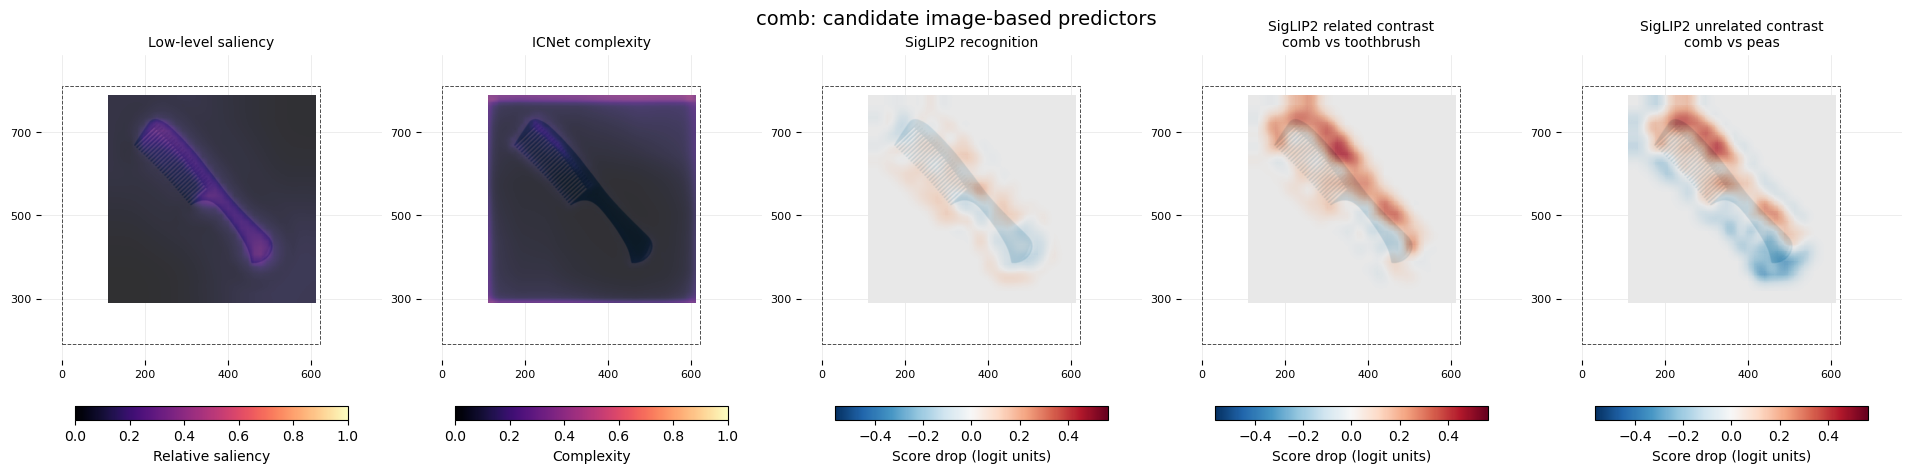

In [4]:
fig = plot_target_comparison(RUN_DIR, TARGET_TO_INSPECT)
plt.show()

## Compare map detail with the earlier run

If the earlier `baseline_v1` results are present, compare recognition and related-competitor maps for the selected target. Each panel uses its own symmetric color scale because smaller, softer masks cause smaller logit changes. Compare spatial structure, not color intensity across runs.

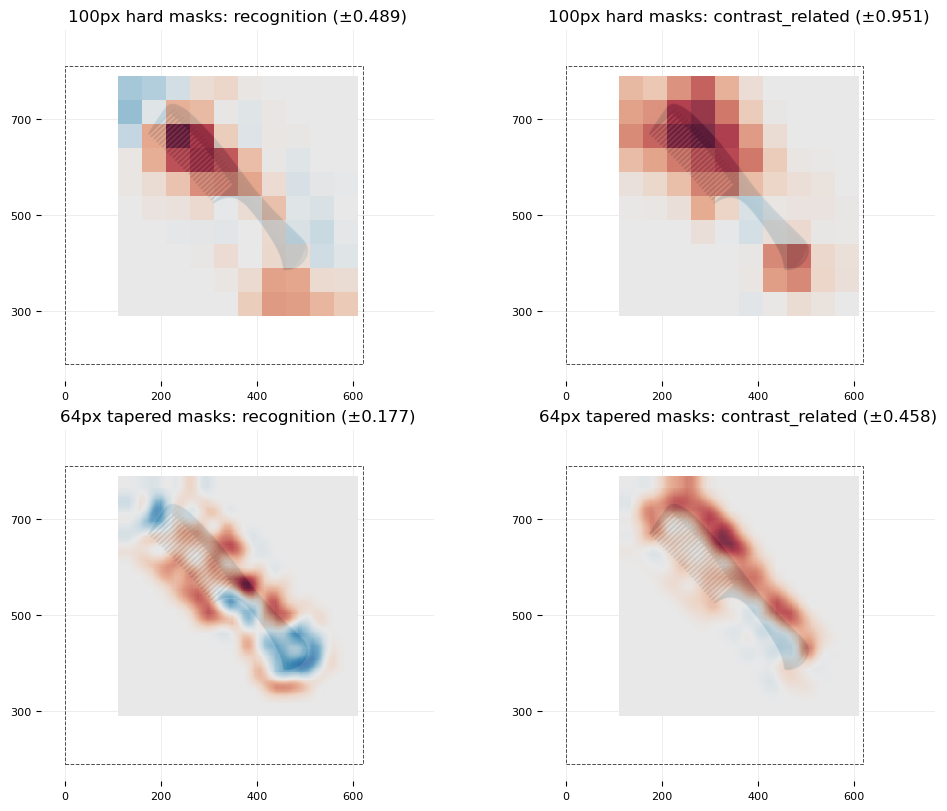

In [5]:
from matplotlib.colors import TwoSlopeNorm
from lwl_models.plotting import draw_map
BASELINE_DIR = ROOT / "outputs" / "model_predictions" / "baseline_v1"
if BASELINE_DIR.is_dir():
    _, baseline_maps = load_run(BASELINE_DIR)
    with Image.open(ROOT / "stim_images" / f"{TARGET_TO_INSPECT}.jpeg") as source:
        reference = source.convert("RGB")
    fig, axes = plt.subplots(2, 2, figsize=(10, 8), layout="constrained")
    for row, (name, archive) in enumerate((("100px hard masks", baseline_maps),
                                            ("64px tapered masks", maps))):
        for col, key in enumerate(("recognition", "contrast_related")):
            values = archive[TARGET_TO_INSPECT][key]
            limit = max(float(np.max(np.abs(values))), 1e-8)
            draw_map(axes[row, col], reference, values, "RdBu_r",
                     TwoSlopeNorm(vmin=-limit, vcenter=0, vmax=limit))
            axes[row, col].set_title(f"{name}: {key} (±{limit:.3f})")
    plt.show()
else:
    print("Earlier baseline run is absent; skipping this optional comparison.")

## All targets: visual saliency and complexity

These two hypotheses are word-independent. The current low-level baseline processes isolated images; full two-image displays are a later control. ICNet complexity should be interpreted separately from bottom-up saliency.

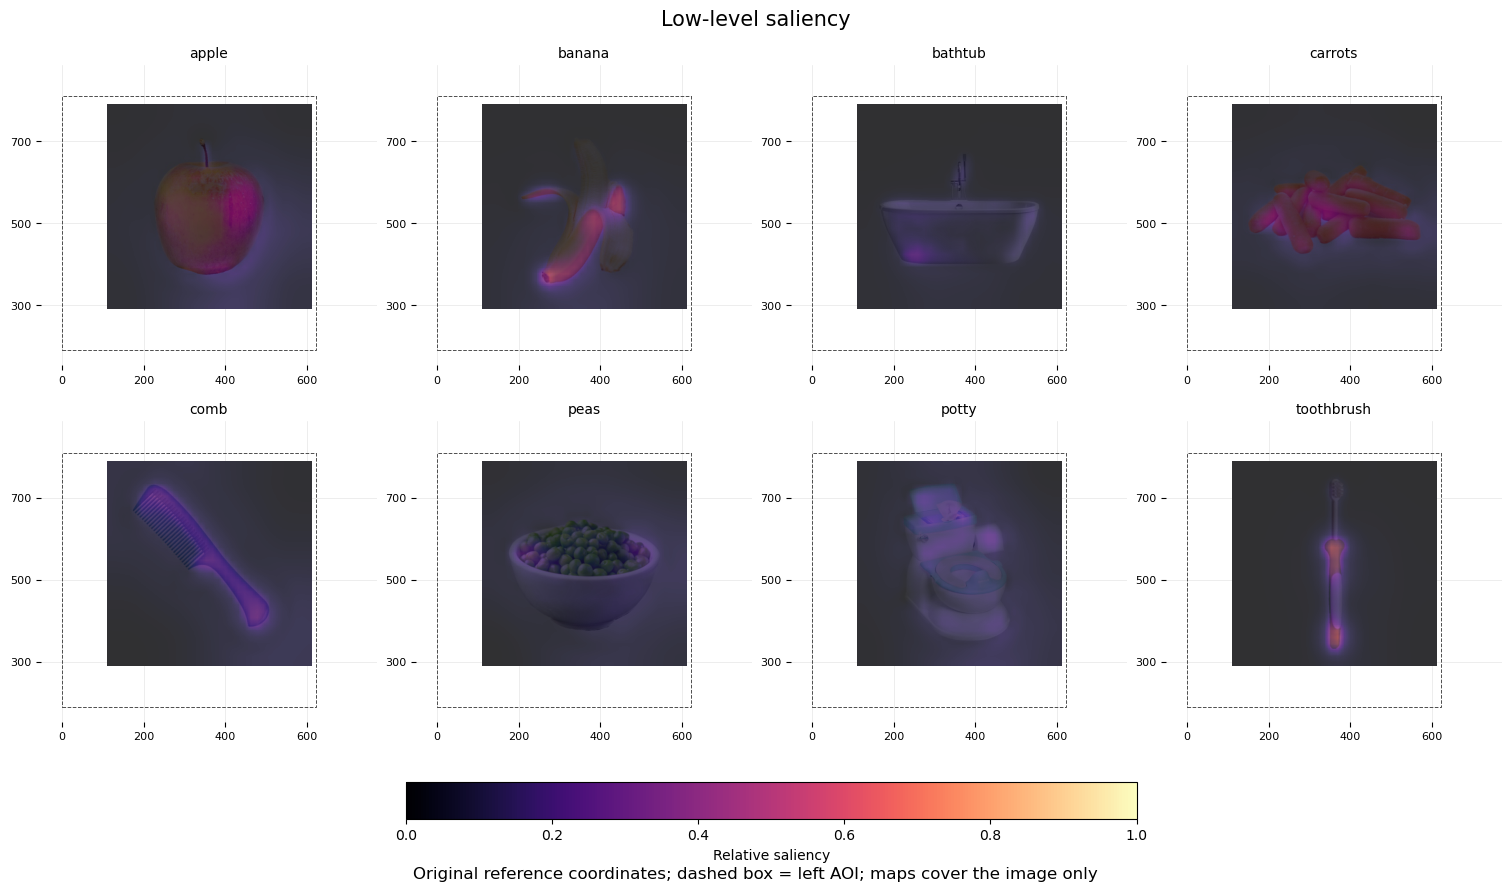

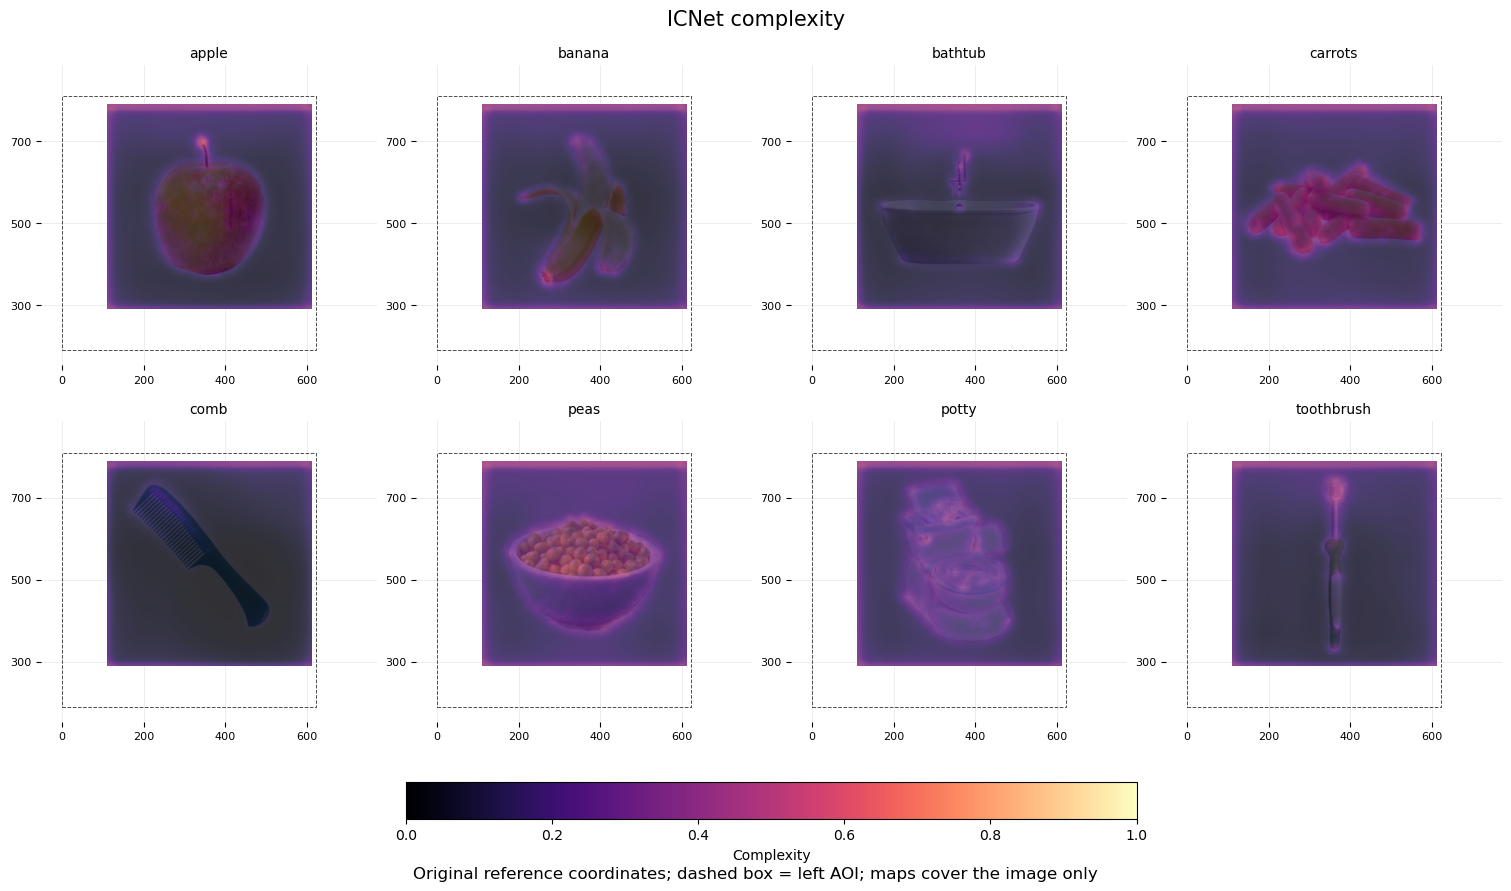

In [6]:
for model_key in ("low_level", "icnet"):
    fig = plot_model_overview(RUN_DIR, model_key)
    plt.show()

## All targets: recognition and competitor contrast

For a patch `r`, let `drop(word, r)` be the intact match logit minus the ablated match logit. Then:

```
recognition(r) = drop(target_word, r)
contrast(r, competitor) = drop(target_word, r) - drop(competitor_word, r)
```

Subtracting a fixed distractor-image score would cancel and reproduce recognition. Here, both word scores respond to the target ablation, allowing the competitor to change spatial importance. Scores are averaged across overlapping patches without taking absolute values or independently rescaling each target.

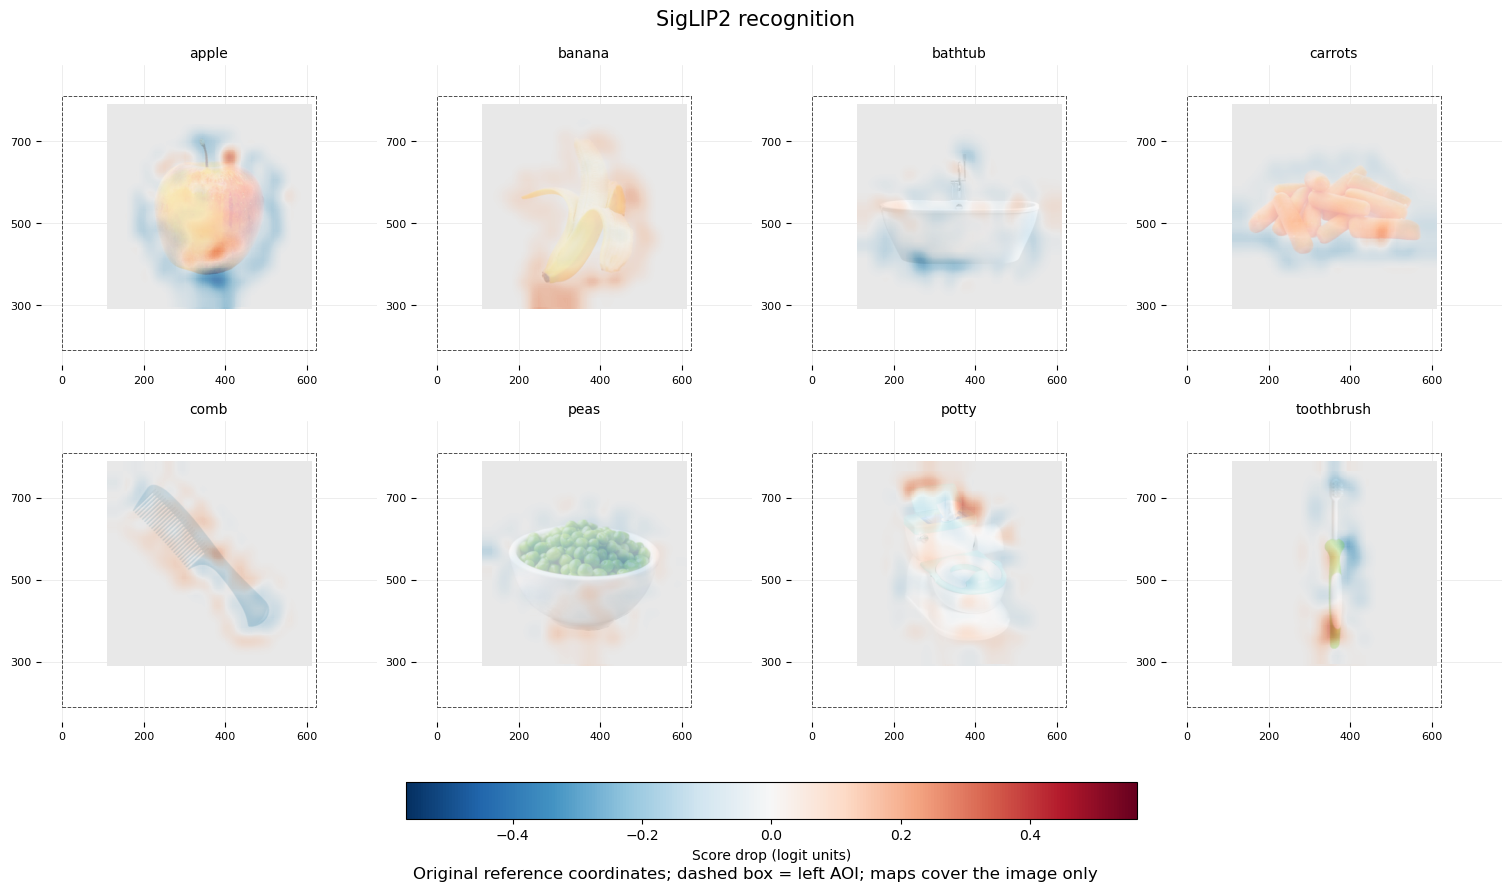

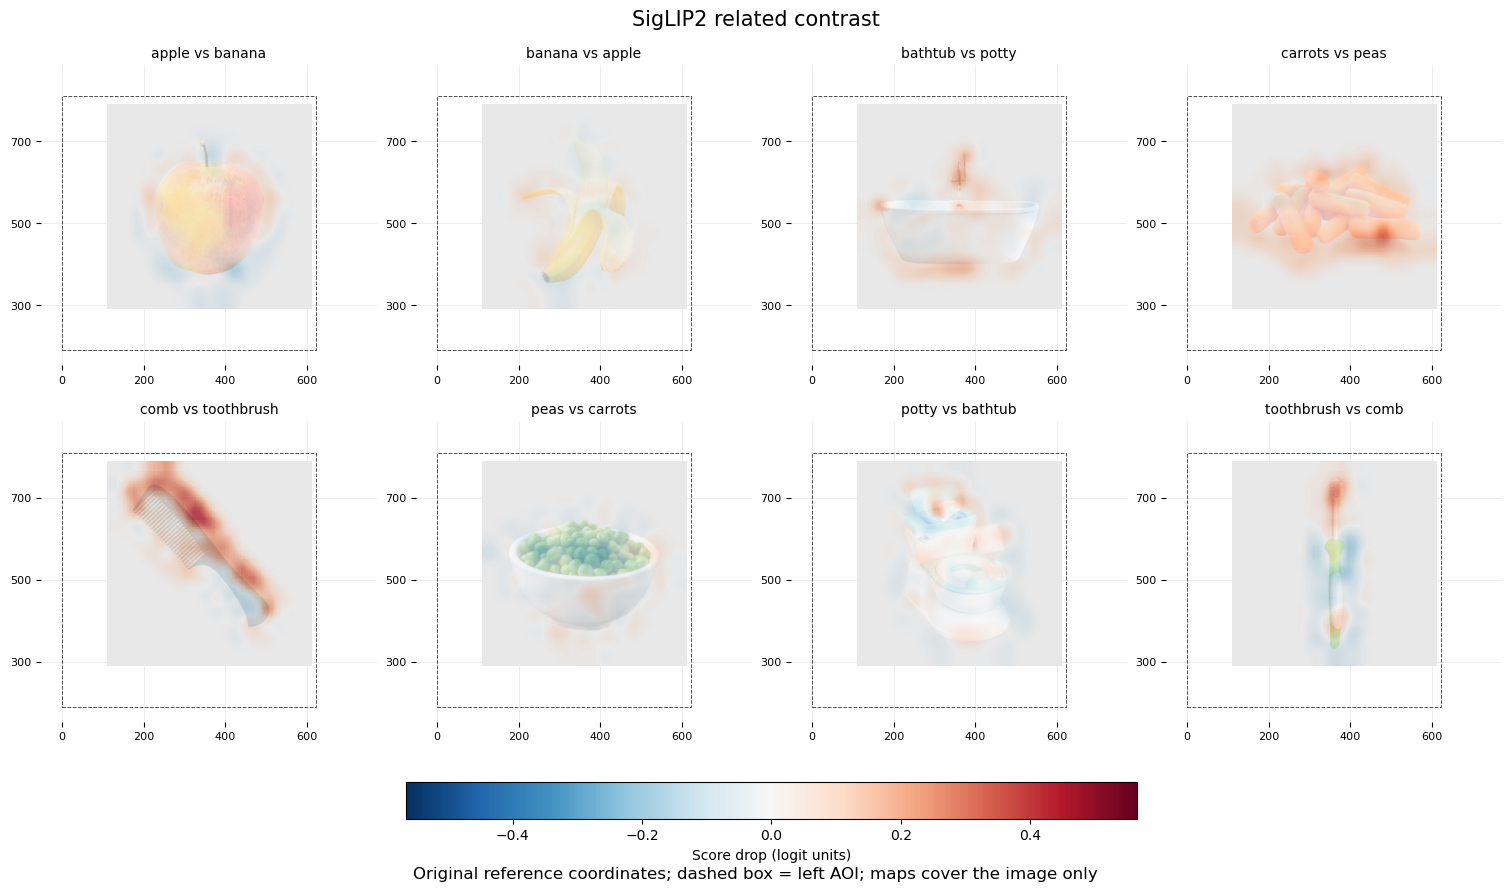

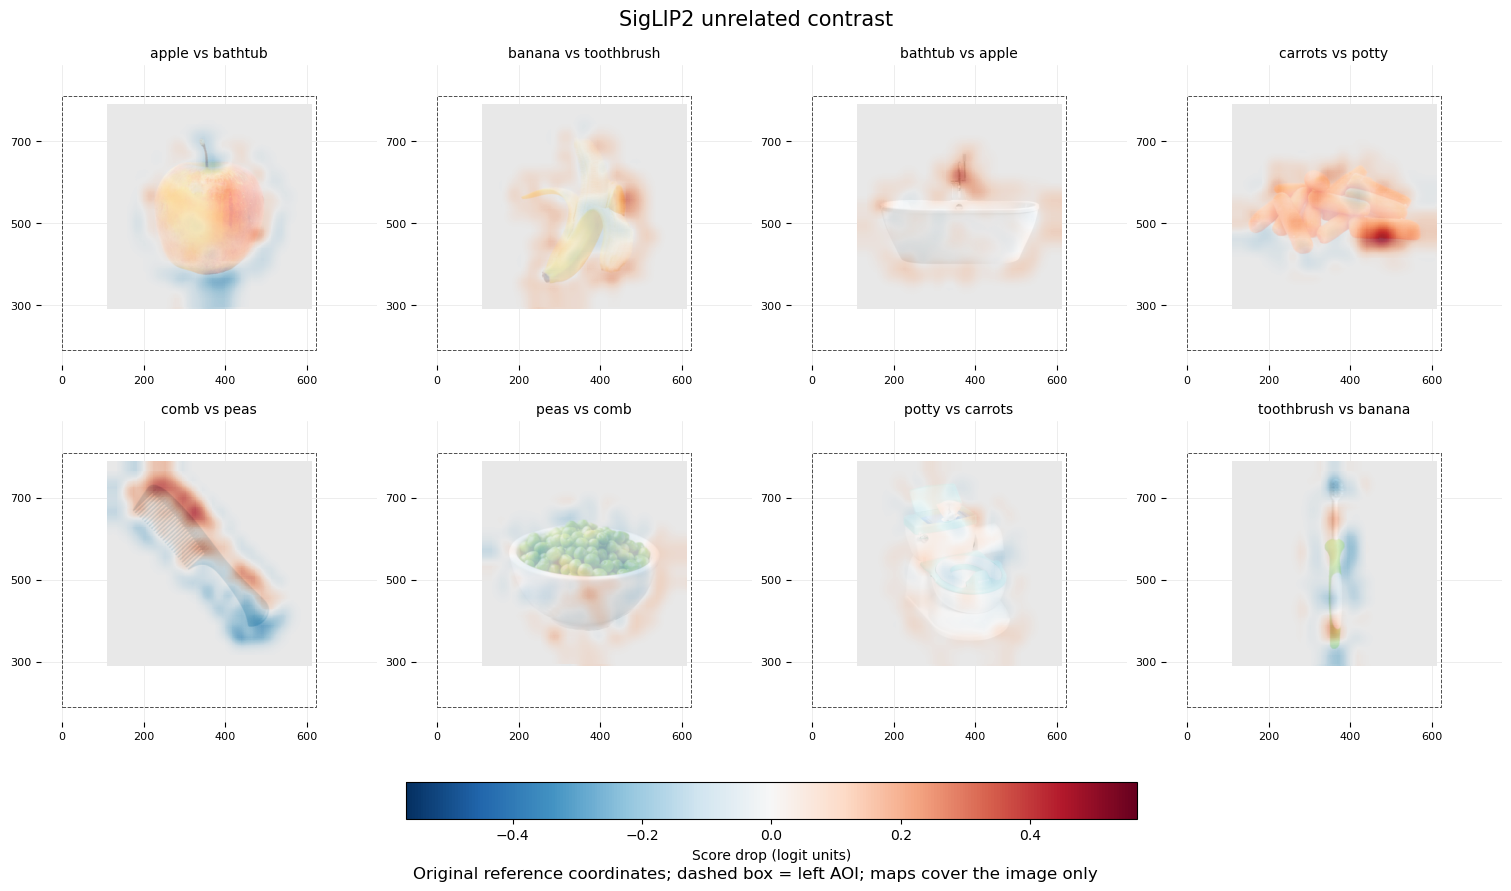

In [7]:
for model_key in ("recognition", "contrast_related", "contrast_unrelated"):
    fig = plot_model_overview(RUN_DIR, model_key)
    plt.show()

## Where does changing the competitor change predicted importance?

This is the Related-minus-Unrelated **model** contrast difference. It is not a measured condition effect in the children. A nonzero map establishes that these model hypotheses make different spatial predictions; behavioral testing still requires condition-specific gaze, appropriate baselines, and held-out evaluation.

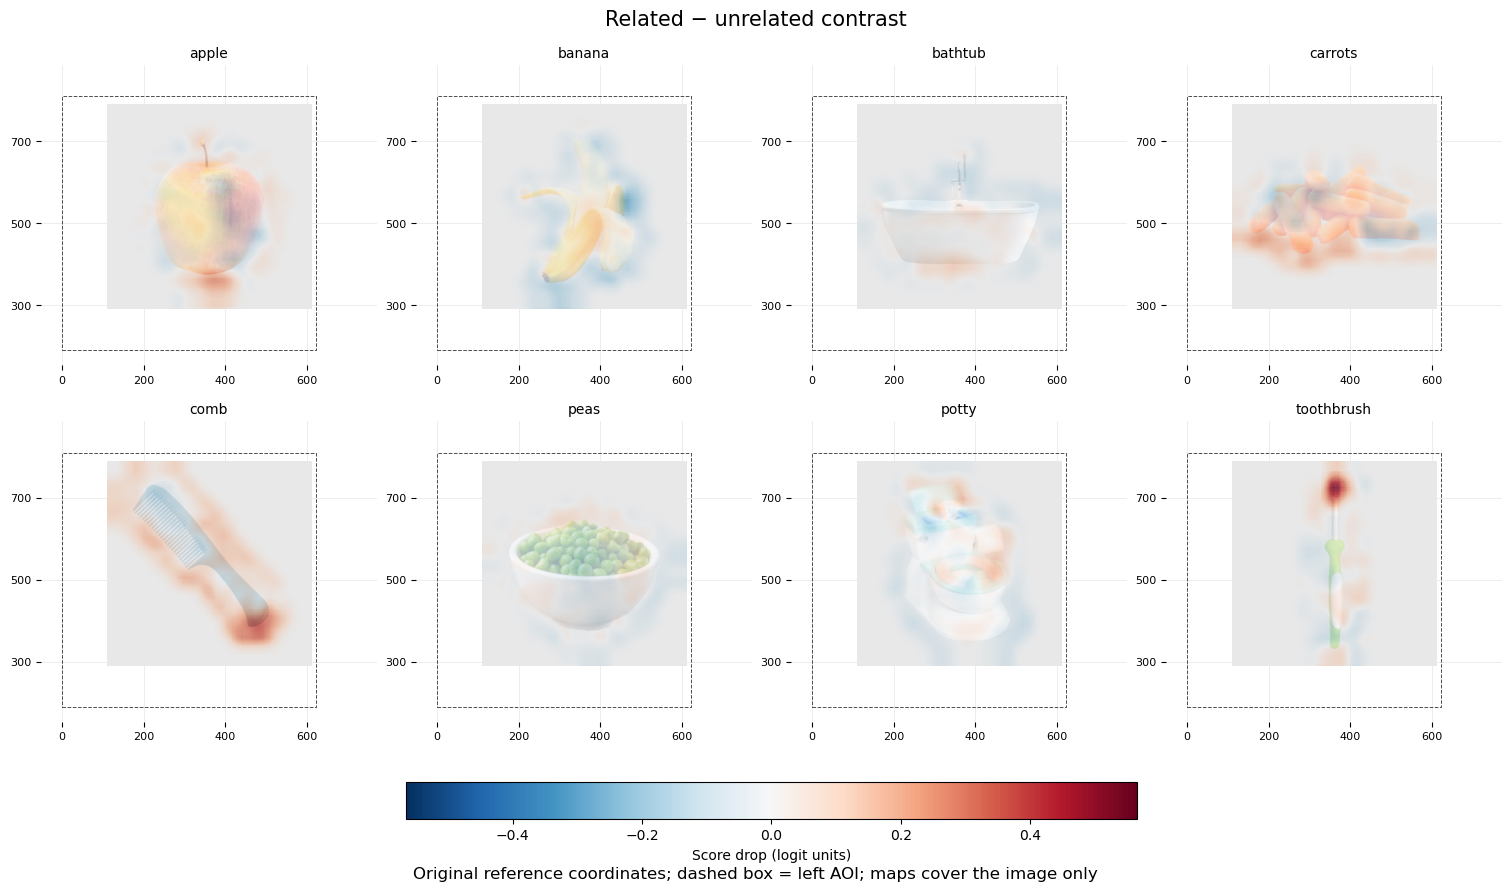

In [8]:
fig = plot_model_overview(RUN_DIR, "contrast_difference")
plt.show()

## Inspect an actual ablation

The default blends a 64×64px region with a blurred image using a tapered Gaussian mask. Its center changes most; pixels outside the box stay untouched. There are 400 overlapping locations on a 24px stride. Displayed importance is regional, not independent pixel-level causation.

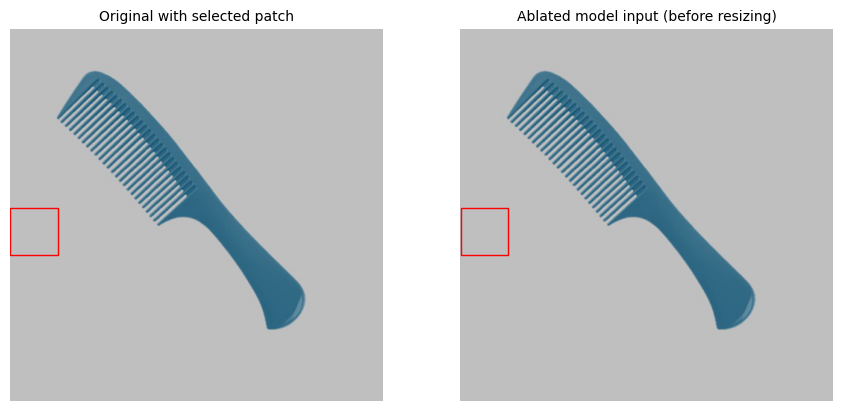

In [9]:
from lwl_models.ablation import ablated_images
from matplotlib.patches import Rectangle
with Image.open(ROOT / "stim_images" / f"{TARGET_TO_INSPECT}.jpeg") as source:
    original = source.convert("RGB")
boxes = maps[TARGET_TO_INSPECT]["boxes"]
PATCH_INDEX = len(boxes) // 2
settings = manifest["settings"]
ablated = next(ablated_images(original, boxes[PATCH_INDEX:PATCH_INDEX+1],
                              mode=settings["ablation_mode"], blur_radius=settings["blur_radius"],
                              mask_shape=settings.get("mask_shape", "hard")))
fig, axes = plt.subplots(1, 2, figsize=(9, 4), layout="constrained")
left, top, right, bottom = boxes[PATCH_INDEX]
for ax, image, title in zip(axes, [original, ablated], ["Original with selected patch", "Ablated model input (before resizing)"]):
    ax.imshow(image)
    ax.add_patch(Rectangle((left, top), right-left, bottom-top,
                           fill=False, edgecolor="red", linewidth=1))
    ax.set_title(title, fontsize=10)
    ax.axis("off")
plt.show()

## Inspect complexity-map edge responses

The table below reports the average native ICNet map in a 4-cell outer band versus the interior (native map: 64×64). This is a diagnostic of the released output, not an instruction to subtract the border. Possible boundary/preprocessing effects need to be distinguished from genuine complexity before interpreting gaze agreement.

In [10]:
rows = []
for target, arrays in maps.items():
    native = arrays["icnet_native"]
    edge = np.ones(native.shape, dtype=bool)
    edge[4:-4, 4:-4] = False
    rows.append({"Target": target, "Native edge mean": float(native[edge].mean()),
                 "Native interior mean": float(native[~edge].mean())})
display(pd.DataFrame(rows).set_index("Target"))

,Native edge mean,Native interior mean
Target,,
apple,0.195813,0.116601
banana,0.213340,0.114968
bathtub,0.206069,0.112897
carrots,0.217901,0.159890
comb,0.150430,0.050550
peas,0.241576,0.232003
potty,0.221657,0.177027
toothbrush,0.205231,0.110568


## Next checks

1. Inspect these maps and intact naming scores without selecting settings using infant gaze.
2. Repeat selected targets with another patch size and a mean-color replacement to assess attribution stability.
3. Preserve target × distractor condition in the gaze data. Condition and screen side are confounded within each target.
4. Verify acquisition coordinates and actual word onset before spatial or temporal behavioral comparison.
5. Compare held-out gaze predictions using shared spatial support and calibration; do not treat the model maps as fixation probabilities directly.

The current run does not implement actual-distractor-image contrast, train on gaze, or test causal explanations. Those remain explicit later steps in [RESEARCH_PLAN.md](../RESEARCH_PLAN.md).